# Week 01 — YCB-V Dataset Understanding

### Side Quest: Dataset Understanding I

This notebook uses the small **YCB-V BOP'19 test subset (~660 MB)** instead of downloading the full original dataset.

**Week 1:** understand the data and annotations — **no model training**.


# YCB-Video Dataset Notes
*italicized text*
YCB-Video is a large RGB-D video dataset introduced with the PoseCNN work for **6D object pose estimation in cluttered scenes**.

The official dataset/toolbox describes:

- **21 YCB objects**
- **92 videos**
- **133,827 frames**
- RGB-D data
- accurate 6D object pose annotations

The PoseCNN paper reports a resolution of **640 × 480** and describes 80 videos used for training and 12 held-out videos used for testing in the original benchmark.

## Quick notes

- **RGB:** color image
- **Depth:** depth/distance information
- **Mask:** pixel-level object region
- **Bounding box:** rectangle around an object
- **Camera info:** camera intrinsic parameters
- **Pose:** object rotation + translation

## 1. Install/import
Only the libraries needed for downloading, reading JSON/images, and simple visualization.


In [1]:
%pip -q install huggingface_hub pillow matplotlib pandas


In [2]:
from pathlib import Path
import json
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from huggingface_hub import hf_hub_download

print("Ready")


Ready


## 2. Download and extract YCB-V BOP'19 subset
Downloads `ycbv_base.zip` + `ycbv_test_bop19.zip`. The test archive is about 660 MB.


In [3]:
DATASETS_DIR = Path("datasets")
DOWNLOAD_DIR = DATASETS_DIR / "downloads"
DATASET_ROOT = DATASETS_DIR / "ycbv"

DATASETS_DIR.mkdir(exist_ok=True)
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

REPO_ID = "bop-benchmark/ycbv"

base_zip = Path(hf_hub_download(
    repo_id=REPO_ID,
    filename="ycbv_base.zip",
    repo_type="dataset",
    local_dir=DOWNLOAD_DIR
))

test_zip = Path(hf_hub_download(
    repo_id=REPO_ID,
    filename="ycbv_test_bop19.zip",
    repo_type="dataset",
    local_dir=DOWNLOAD_DIR
))

# Base archive creates the ycbv folder.
if not DATASET_ROOT.exists():
    with zipfile.ZipFile(base_zip, "r") as z:
        z.extractall(DATASETS_DIR)

# Test archive is extracted inside ycbv.
if not (DATASET_ROOT / "test").exists():
    DATASET_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(test_zip, "r") as z:
        z.extractall(DATASET_ROOT)

print("Dataset root:", DATASET_ROOT.resolve())
print("Exists:", DATASET_ROOT.exists())
print("Test folder:", (DATASET_ROOT / "test").exists())


ycbv_base.zip: reconstructing file:   0%|          |  0.00B / 15.8kB            

ycbv_base.zip: downloading bytes:           |  0.00B            

ycbv_test_bop19.zip: reconstructing file:   0%|          |  0.00B /  660MB            

ycbv_test_bop19.zip: downloading bytes:           |  0.00B            

Dataset root: /content/datasets/ycbv
Exists: True
Test folder: True


## 3. Load the dataset structure
YCB-V BOP is a folder of **PNG images + JSON annotations**.


In [4]:
TEST_DIR = DATASET_ROOT / "test"

scene_dirs = sorted([p for p in TEST_DIR.iterdir() if p.is_dir()])

print("Number of test scenes:", len(scene_dirs))
print("First scene folders:", [p.name for p in scene_dirs[:5]])

first_scene = scene_dirs[0]

print("\nFirst scene:", first_scene.name)
for p in sorted(first_scene.iterdir()):
    print(("DIR " if p.is_dir() else "FILE"), p.name)


Number of test scenes: 12
First scene folders: ['000048', '000049', '000050', '000051', '000052']

First scene: 000048
DIR  depth
DIR  mask
DIR  mask_visib
DIR  rgb
FILE scene_camera.json
FILE scene_gt.json
FILE scene_gt_info.json


## 4. Build a Dataset Table

In [23]:
def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

records = []

for scene_dir in scene_dirs:
    scene_gt = load_json(scene_dir / "scene_gt.json")

    for rgb_path in sorted((scene_dir / "rgb").glob("*.png")):
        image_id = int(rgb_path.stem)
        objects = scene_gt.get(str(image_id), [])

        records.append({
            "scene_id": int(scene_dir.name),
            "image_id": image_id,
            "rgb_path": str(rgb_path),
            "depth_path": str(scene_dir / "depth" / rgb_path.name),
            "object_count": len(objects),
        })

dataset_df = pd.DataFrame(records)

print("Rows:", len(dataset_df))
display(dataset_df.head(10))


Rows: 900


,scene_id,image_id,rgb_path,depth_path,object_count
0,48,1,datasets/ycbv/test/000048/rgb/000001.png,datasets/ycbv/test/000048/depth/000001.png,5
1,48,36,datasets/ycbv/test/000048/rgb/000036.png,datasets/ycbv/test/000048/depth/000036.png,5
2,48,47,datasets/ycbv/test/000048/rgb/000047.png,datasets/ycbv/test/000048/depth/000047.png,5
3,48,83,datasets/ycbv/test/000048/rgb/000083.png,datasets/ycbv/test/000048/depth/000083.png,5
4,48,112,datasets/ycbv/test/000048/rgb/000112.png,datasets/ycbv/test/000048/depth/000112.png,5
5,48,1024,datasets/ycbv/test/000048/rgb/001024.png,datasets/ycbv/test/000048/depth/001024.png,5
6,48,1027,datasets/ycbv/test/000048/rgb/001027.png,datasets/ycbv/test/000048/depth/001027.png,5
7,48,1059,datasets/ycbv/test/000048/rgb/001059.png,datasets/ycbv/test/000048/depth/001059.png,5
8,48,1074,datasets/ycbv/test/000048/rgb/001074.png,datasets/ycbv/test/000048/depth/001074.png,5
9,48,1075,datasets/ycbv/test/000048/rgb/001075.png,datasets/ycbv/test/000048/depth/001075.png,5


## 5. Show the RGB images


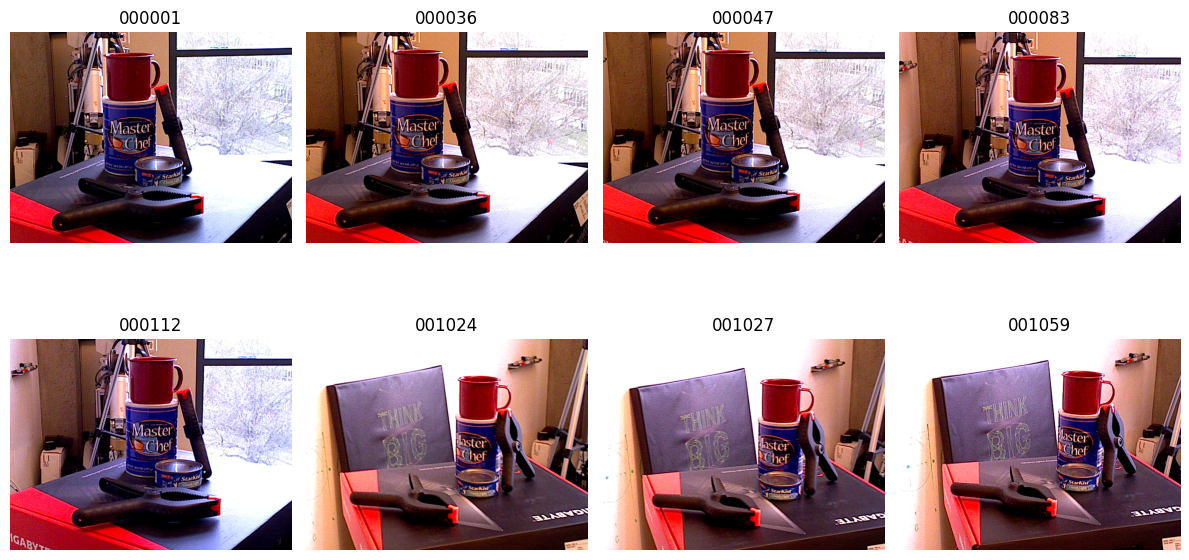

In [27]:
rgb_files = sorted((first_scene / "rgb").glob("*.png"))[:8]

fig, axes = plt.subplots(2, 4, figsize=(12, 7))

for ax, path in zip(axes.ravel(), rgb_files):
    image = Image.open(path).convert("RGB")
    ax.imshow(image)
    ax.set_title(path.stem)
    ax.axis("off")

plt.tight_layout()
plt.show()


## 6. Read one RGB + depth example
Select the first frame and inspect the image arrays.


Scene ID: 000048
Image ID: 1
RGB shape: (480, 640, 3) | dtype: uint8
Depth shape: (480, 640) | dtype: uint16
Raw depth range: 0 to 28800


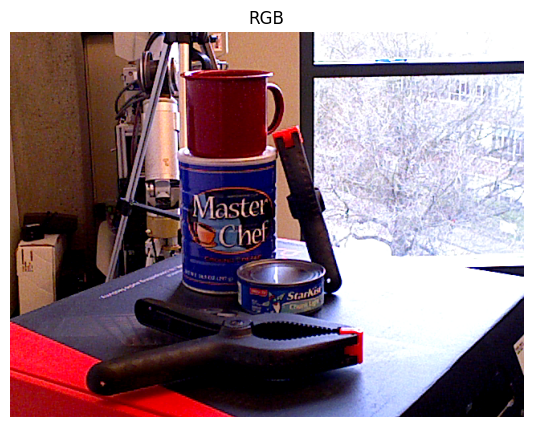

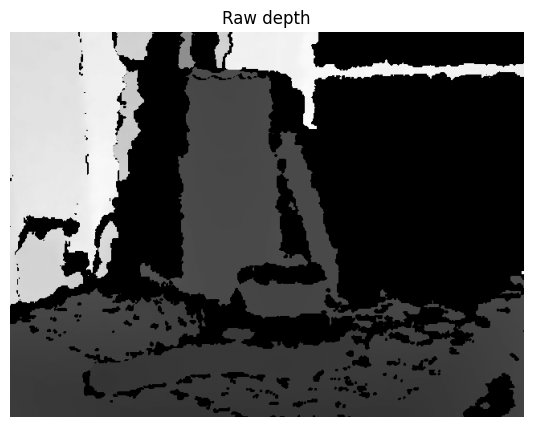

In [7]:
RGB_PATH = rgb_files[0]
IMAGE_ID = int(RGB_PATH.stem)
DEPTH_PATH = first_scene / "depth" / RGB_PATH.name

rgb = np.array(Image.open(RGB_PATH).convert("RGB"))
depth_raw = np.array(Image.open(DEPTH_PATH))

print("Scene ID:", first_scene.name)
print("Image ID:", IMAGE_ID)
print("RGB shape:", rgb.shape, "| dtype:", rgb.dtype)
print("Depth shape:", depth_raw.shape, "| dtype:", depth_raw.dtype)
print("Raw depth range:", depth_raw.min(), "to", depth_raw.max())

plt.figure(figsize=(7, 5))
plt.imshow(rgb)
plt.title("RGB")
plt.axis("off")
plt.show()

plt.figure(figsize=(7, 5))
plt.imshow(depth_raw, cmap="gray")
plt.title("Raw depth")
plt.axis("off")
plt.show()


## 7. Read camera + pose JSON
`scene_camera.json` stores camera information. `scene_gt.json` stores object IDs and 6D poses.
### Camera Intrinsic Matrix :

\begin{bmatrix}
f_x & 0 & c_x \\
0 & f_y & c_y \\
0 & 0 & 1
\end{bmatrix}


- **fx, fy** → focal length in pixels  
- **cx, cy** → principal point (near the image center)  
- **0** → no skew between image axes  
- **1** → homogeneous-coordinate term


In [8]:
scene_camera = load_json(first_scene / "scene_camera.json")
scene_gt = load_json(first_scene / "scene_gt.json")
scene_gt_info = load_json(first_scene / "scene_gt_info.json")

camera = scene_camera[str(IMAGE_ID)]
objects = scene_gt[str(IMAGE_ID)]
objects_info = scene_gt_info[str(IMAGE_ID)]

K = np.array(camera["cam_K"]).reshape(3, 3)
depth_scale = camera["depth_scale"]

print("Camera intrinsic matrix K:")
print(K)
print("\nDepth scale:", depth_scale)

print("\nObjects in this frame:", len(objects))

for i, obj in enumerate(objects):
    R = np.array(obj["cam_R_m2c"]).reshape(3, 3)
    t = np.array(obj["cam_t_m2c"])
    print(f"\nObject #{i}")
    print("obj_id:", obj["obj_id"])
    print("translation (mm):", t)
    print("rotation matrix:")
    print(R)


Camera intrinsic matrix K:
[[1.066778e+03 0.000000e+00 3.129869e+02]
 [0.000000e+00 1.067487e+03 2.413109e+02]
 [0.000000e+00 0.000000e+00 1.000000e+00]]

Depth scale: 0.1

Objects in this frame: 5

Object #0
obj_id: 1
translation (mm): [-31.67702542 -17.36881681 865.05676506]
rotation matrix:
[[ 0.61554263 -0.78720027 -0.03771989]
 [-0.19894987 -0.10889927 -0.97394011]
 [ 0.76257894  0.60700606 -0.22364551]]

Object #1
obj_id: 6
translation (mm): [ 19.82695919  56.52491051 810.72270268]
rotation matrix:
[[-0.88880015  0.45524947 -0.05275502]
 [ 0.15161265  0.18344755 -0.97126692]
 [-0.4324912  -0.87126042 -0.23206974]]

Object #2
obj_id: 14
translation (mm): [ -23.31009354 -112.62940453  848.16794828]
rotation matrix:
[[ 0.80027033 -0.59848337 -0.03721742]
 [-0.16673639 -0.16247692 -0.97252258]
 [ 0.5759917   0.78448627 -0.22981459]]

Object #3
obj_id: 19
translation (mm): [ 52.33599372 -13.03129664 861.58992891]
rotation matrix:
[[-0.09489741  0.35613863 -0.92960195]
 [-0.34937416  0

## 8. Scale depth to millimeters
In BOP format: `depth_mm = depth_image * depth_scale`.


Valid depth min: 590.00 mm  |  59.00 cm
Valid depth max: 2880.00 mm  |  288.00 cm


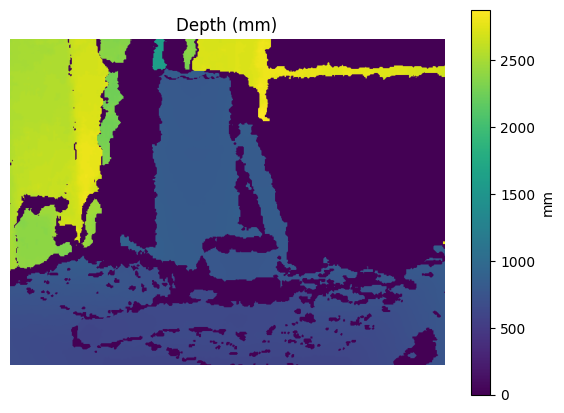

In [29]:
depth_mm = depth_raw.astype(np.float32) * depth_scale
depth_cm = depth_mm / 10.0

valid = depth_mm > 0

min_mm = depth_mm[valid].min()
max_mm = depth_mm[valid].max()

min_cm = depth_cm[valid].min()
max_cm = depth_cm[valid].max()

print(f"Valid depth min: {min_mm:.2f} mm  |  {min_cm:.2f} cm")
print(f"Valid depth max: {max_mm:.2f} mm  |  {max_cm:.2f} cm")

plt.figure(figsize=(7, 5))
plt.imshow(depth_mm)
plt.title("Depth (mm)")
plt.axis("off")
plt.colorbar(label="mm")
plt.show()


## 9. Show masks
BOP stores full object masks in `mask/` and visible masks in `mask_visib/`.


Full masks: 5
Visible masks: 5


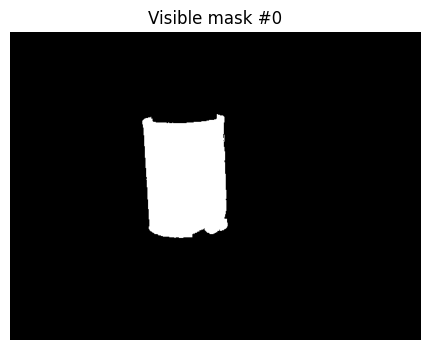

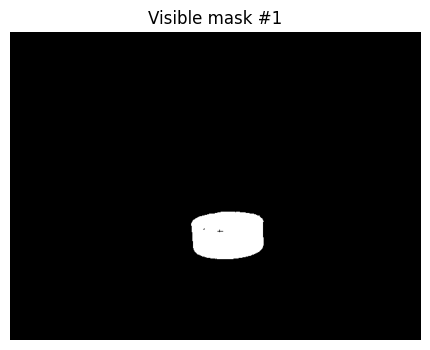

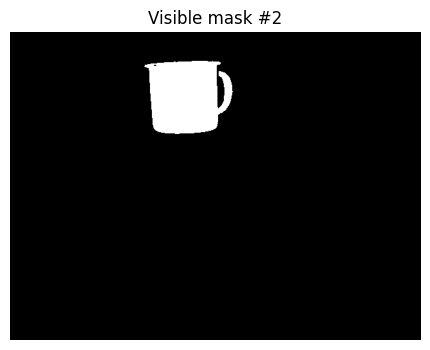

In [10]:
mask_files = sorted((first_scene / "mask").glob(f"{IMAGE_ID:06d}_*.png"))
visible_mask_files = sorted(
    (first_scene / "mask_visib").glob(f"{IMAGE_ID:06d}_*.png")
)

print("Full masks:", len(mask_files))
print("Visible masks:", len(visible_mask_files))

for i, path in enumerate(visible_mask_files[:3]):
    mask = np.array(Image.open(path))

    plt.figure(figsize=(6, 4))
    plt.imshow(mask, cmap="gray")
    plt.title(f"Visible mask #{i}")
    plt.axis("off")
    plt.show()


## 10. Draw bounding boxes
Bounding boxes are stored in `scene_gt_info.json` as `(x, y, width, height)`.


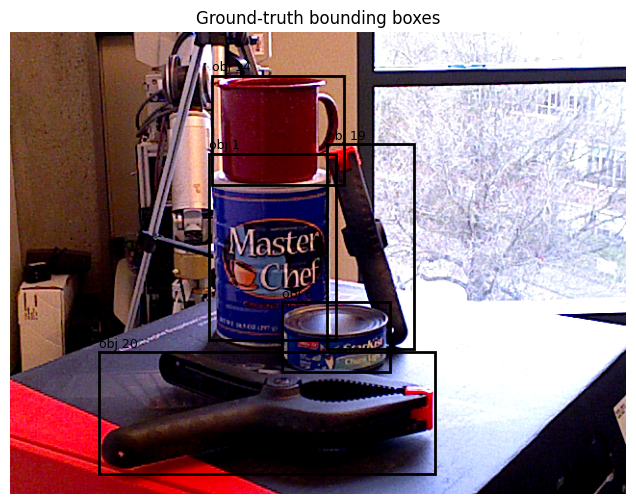

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(rgb)

for i, info in enumerate(objects_info):
    x, y, w, h = info["bbox_obj"]

    rect = Rectangle(
        (x, y),
        w,
        h,
        fill=False,
        linewidth=2
    )
    ax.add_patch(rect)
    ax.text(x, max(0, y - 5), f"obj {objects[i]['obj_id']}", fontsize=9)

ax.set_title("Ground-truth bounding boxes")
ax.axis("off")
plt.show()
